MCS 320 Midterm Two, Friday 13 November 2026

Submit to gradescope before, or at the latest at 1:50pm.

# Question 1

Define the piecewise function $f$ as follows:

$$
         f(x) = \left\{
           \begin{array}{lcl}
              1-(x+1)^2 & & \mbox{if } x < -1, \\
              1 & & \mbox{if } x \in [-1, 1], \\
              1+(x-1)^2 & & \mbox{if } x > 1. \\
           \end{array}
         \right.
$$

Make a plot of $f$ for $x \in [-2, 2]$.

What is the derivative of $f$?

## answer to question 1

In [1]:
f(x) = piecewise([((-oo, -1), 1-(x+1)^2), ([-1, 1],1), ((1, oo), 1+(x-1)^2)])
f

x |--> piecewise(x|-->-(x + 1)^2 + 1 on (-oo, -1), x|-->1 on [-1, 1], x|-->(x - 1)^2 + 1 on (1, +oo); x)

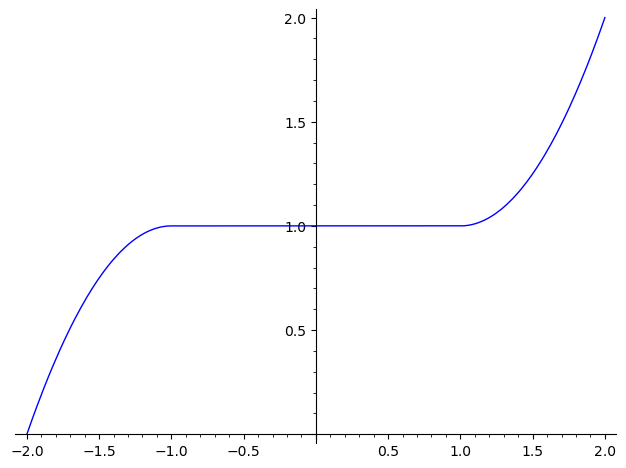

In [2]:
plot(f, -2, 2)

In [3]:
df = diff(f(x),x)
df

piecewise(x|-->-2*x - 2 on (-oo, -1), x|-->0 on [-1, 1], x|-->2*x - 2 on (1, +oo); x)

# Question 2

Consider the recurrence:

$$
      \begin{eqnarray*}
         R(n,k) & = & (k+1) R(n-1,k) + (n-k)R(n-1,k-1), \mbox{~~~~~~~~} \\
         R(n,k) & = & 0 \mbox{ if } n < 0 \mbox{ or } k < 0, \\
         R(n,0) & = & 1 \mbox{ if } n \geq 0.
      \end{eqnarray*}
$$                                                      

Define a function ``R`` which returns $R(n,k)$, using a dictionary for memoization.

Make sure your function can compute $R(100,50)$.

## answer to question 2

In [4]:
reset()

In [5]:
def R(n, k, D={}):
    if (n,k) in D:
        return D[(n,k)]
    else:
        if k < 0 or n < 0:
            result = 0
        elif k == 0:
            result = 1
        else:
            result = (k+1)*R(n-1,k) + (n-k)*R(n-1,k-1)
            D[(n,k)] = result
        return result

In [6]:
R(100,50)

12626583048565731758704803903613273608195677189975104100350973856449564133356757386852425614117017819889941988926638004335803974817249421258019632694790596628

# Question 3

Consider the curve defined by
$(x^2 - 4 y + y^2)^2 - 16 (x^2 + y^2) = 0$.

Compute the tangent line at the point $(4,0)$.

What is the slope of the tangent line?

## answer to question 3

In [7]:
reset()

In [8]:
x, y = var('x, y')

In [9]:
p = (x^2 - 4*y + y^2)^2 - 16*(x^2 + y^2)
show(p)

(x^2 + y^2 - 4*y)^2 - 16*x^2 - 16*y^2

In [10]:
tp = taylor(p, (x, 4), (y, 0), 1)
show(tp)

128*x - 128*y - 512

We see that the slope equals one, and we can also compute it as follows:

In [11]:
-tp.coefficient(x, 1)/tp.coefficient(y,1)

1

# Question 4

Explain the main differences between a Python and a SageMath function.

1. Give an example from the course for when a SageMath function does not work,
for which a Python function must be used.

2. Give an example from the course for when a Python function does not work,
for which a SageMath function must be used.

## answer to question 4

In [12]:
reset()

The main difference between SageMath and Python functions is that SageMath functions are expressions which are evaluated during their definition, while Python functions are only parsed during their definition.

Recursive formulas such as in question 2 cannot be defined via SageMath functions and for those Python functions must be used.

Python functions cannot be differentiated directly, such as in question 1, and for functions we want to differentiate, SageMath functions must be used.

# Question 5

Consider the surface $x^2 + 2 y^2 + 3 z^2  = 4$ and the point $P = (3, 2, 1)$.

1. To locate those points on the surface closest to $P$, what system must be solved?

2. Solve the system and select the coordinates of the point(s) on the surface closest to $P$.

## answer to question 5

In [13]:
reset()

In [14]:
target(x, y, z) = (x-3)^2 + (y-2)^2 + (z-1)^2
target

(x, y, z) |--> (x - 3)^2 + (y - 2)^2 + (z - 1)^2

In [15]:
constraint(x, y, z) = x^2 + 2*y^2 + 3*z^2 - 4
constraint

(x, y, z) |--> x^2 + 2*y^2 + 3*z^2 - 4

In [16]:
dt = target.diff()
dt

(x, y, z) |--> (2*x - 6, 2*y - 4, 2*z - 2)

In [17]:
dc = constraint.diff()
dc

(x, y, z) |--> (2*x, 4*y, 6*z)

In [18]:
x, y, z, Lambda = var('x, y, z, Lambda')
eqs = [dt(x,y,z)[k] - Lambda*dc(x, y, z)[k] for k in range(3)]
eqs.append(constraint(x,y,z))
eqs

[-2*Lambda*x + 2*x - 6,
 -4*Lambda*y + 2*y - 4,
 -6*Lambda*z + 2*z - 2,
 x^2 + 2*y^2 + 3*z^2 - 4]

In [19]:
sols = solve(eqs, (x,y,z,Lambda), solution_dict=True)
sols

[{x: 4.593912491264904 + 0.39852002833550326*I,
  y: 5.899736772684213 + 2.238981075456098*I,
  z: -1.760474334670377 + 5.348854671015658*I,
  Lambda: 0.3518396005053328 + 0.056227649365049905*I},
 {x: 4.593912491264904 - 0.39852002833550326*I,
  y: 5.899736772684213 - 2.2389810754560977*I,
  z: -1.7604743346703768 - 5.348854671015658*I,
  Lambda: 0.3518396005053328 - 0.056227649365049905*I},
 {x: 1.6278841433480609,
  y: 0.7446664409075516,
  z: 0.2833945486178233,
  Lambda: -0.8428831286948613},
 {x: 6.025555736121173 + 2.969856600000124*I,
  y: -2.034766944523021 + 4.040299960994601*I,
  z: -0.8079202412186893 + 0.5994398886939406*I,
  Lambda: 0.5994300765409304 + 0.19743162009356258*I},
 {x: 6.025555736121173 - 2.969856600000124*I,
  y: -2.034766944523021 - 4.040299960994601*I,
  z: -0.8079202412186893 - 0.5994398886939406*I,
  Lambda: 0.5994300765409304 - 0.19743162009356258*I},
 {x: -1.8668206312548115,
  y: -0.47460610124036207,
  z: -0.14660539579009785,
  Lambda: 2.60701030927

In [20]:
v = [target(sol[x], sol[y], sol[z]) for sol in sols]
v

[-8.413378282471486 - 10.797466309474189*I,
 -8.41337828247148 + 10.797466309474192*I,
 3.972087641610052,
 3.1985072280649214 - 16.799883130309247*I,
 3.1985072280649214 + 16.799883130309247*I,
 31.124322346758476]

Ignoring the complex solutions, we see that the solution at index 2 has the smallest value.

In [21]:
mpt = (sols[2][x], sols[2][y], sols[2][z])
mpt

(1.6278841433480609, 0.7446664409075516, 0.2833945486178233)

In [22]:
target(*mpt)

3.972087641610052

# Question 6

For variables $a$, $b$, $c$,
define a function which returns the tridiagonal matrix $A_n$:

$$
         A_n = \left[
           \begin{array}{ccccc}
             a & b & 0 &  &  \\
             c & a & b & \ddots & \\
             0 & c & a & \ddots & 0 \\
              & \ddots & \ddots & \ddots & \vdots \\
              &  & 0 & \cdots & a \\
           \end{array}
         \right].
$$
      Observe: $a$ appears on the diagonal of $A_n$,
      $b$ above, and $c$ below the diagonal, and 0 elsewhere.

Show your function works for $n = 8$ and compute the determinant of $A_8$.

## answer to question 6

In [23]:
reset()

In [24]:
a, b, c = var('a, b, c')

In [25]:
idx = lambda i,j: (a if i==j else (b if j==i+1 else (c if j==i-1 else 0)))

In [26]:
def A(n):
    return matrix(n, n, idx)

In [27]:
A8 = A(8)
show(A8)

[a b 0 0 0 0 0 0]
[c a b 0 0 0 0 0]
[0 c a b 0 0 0 0]
[0 0 c a b 0 0 0]
[0 0 0 c a b 0 0]
[0 0 0 0 c a b 0]
[0 0 0 0 0 c a b]
[0 0 0 0 0 0 c a]

In [28]:
det(A8)

a^8 - 7*a^6*b*c + 15*a^4*b^2*c^2 - 10*a^2*b^3*c^3 + b^4*c^4

# Question 7

Let $P$ be the convex polytope spanned by the points in $S$, with

$$
    S = \{ (1,0,0), (2,0,0), (0,1,0), (3,1,0), (1,2,0), (2,2,0), (1,3/2, 1) \}.
$$

Compute the inequalities which define the hyperplane representation of $P$.

## answer to question 7

In [29]:
reset()

In [30]:
S = [(1, 0, 0), (2,0,0), (0,1,0), (3,1,0), (1,2,0), (2,2,0), (1,3/2, 1)]
S

[(1, 0, 0), (2, 0, 0), (0, 1, 0), (3, 1, 0), (1, 2, 0), (2, 2, 0), (1, 3/2, 1)]

In [31]:
P = Polyhedron(vertices=S)
P

A 3-dimensional polyhedron in QQ^3 defined as the convex hull of 7 vertices (use the .plot() method to plot)

In [32]:
P.plot()

Graphics3d Object

In [33]:
P.Hrepresentation()

(An inequality (0, 0, 1) x + 0 >= 0,
 An inequality (2, 2, -3) x - 2 >= 0,
 An inequality (2, -2, -1) x + 2 >= 0,
 An inequality (0, 2, -3) x + 0 >= 0,
 An inequality (0, -2, -1) x + 4 >= 0,
 An inequality (-2, -2, -3) x + 8 >= 0,
 An inequality (-2, 2, -5) x + 4 >= 0)